# 10 - Sharper TotalSegmentator Skull for the Single Patient

This notebook improves the bony reconstruction while preserving a deep-learning-only
segmentation workflow:

- The dedicated TotalSegmentator `craniofacial_structures` nnU-Net task runs on
  the sharp `BONE_HR60F` CT reconstruction.
- Its predicted `skull`, `mandible`, `teeth_upper`, and `teeth_lower` labels are
  combined into one complete bony-head mask.
- The mesh uses every voxel step (`step_size=1`) and only two Taubin smoothing
  iterations to retain substantially more surface detail.
- The brain mask is the pretrained TotalSegmentator prediction from notebook 09,
  also meshed at `step_size=1` with six smoothing iterations to reduce voxel
  stair-stepping while retaining the high-resolution surface.

No HU-threshold skull mask is used. Label union and mesh smoothing occur only
after neural-network inference. These outputs are research visualizations and
are not intended for diagnosis or clinical decision-making.

In [1]:
from pathlib import Path
import importlib.metadata as metadata
import gc
import json
import time

import dicom2nifti
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import plotly.graph_objects as go
import pydicom
import torch
import trimesh
from IPython.display import IFrame, display
from scipy import ndimage as ndi
from skimage import measure
from totalsegmentator.python_api import totalsegmentator

STARTED = time.time()
DATASET_ROOT = Path(r"F:\csstdy\Single_Patient_Study")
OUTPUT_DIR = Path(r"F:\csstdy\outputs\10_totalsegmentator_sharp_skull")
INPUT_DIR = OUTPUT_DIR / "input"
SEGMENTATION_DIR = OUTPUT_DIR / "craniofacial_segmentations"
MESH_DIR = OUTPUT_DIR / "meshes"
for directory in (INPUT_DIR, SEGMENTATION_DIR, MESH_DIR):
    directory.mkdir(parents=True, exist_ok=True)

BONE_CT_NIFTI = INPUT_DIR / "CASE_001_bone_kernel_ct.nii.gz"
PRIOR_BRAIN_NIFTI = Path(
    r"F:\csstdy\outputs\09_totalsegmentator_dl_skull_brain\segmentations\brain.nii.gz"
)
REPORT_PATH = OUTPUT_DIR / "craniofacial_totalsegmentator_report.json"
SUMMARY_PATH = OUTPUT_DIR / "reconstruction_summary.json"
SKULL_GLB_CACHE = MESH_DIR / "CASE_001_totalsegmentator_sharp_skull.glb"
CRANIOFACIAL_LABELS = ["skull", "mandible", "teeth_upper", "teeth_lower"]
FORCE_RERUN = False

assert DATASET_ROOT.exists(), f"Dataset not found: {DATASET_ROOT}"
assert PRIOR_BRAIN_NIFTI.exists(), "Run notebook 09 first to create the TotalSegmentator brain mask."
assert torch.cuda.is_available(), "CUDA GPU is required for this notebook execution."

print("TotalSegmentator:", metadata.version("TotalSegmentator"))
print("nnU-Net:", metadata.version("nnunetv2"))
print("PyTorch:", torch.__version__)
print("Inference device:", torch.cuda.get_device_name(0))
print("Craniofacial labels:", CRANIOFACIAL_LABELS)

TotalSegmentator: 2.18.0
nnU-Net: 2.8.1
PyTorch: 2.14.0+cu130
Inference device: NVIDIA GeForce RTX 4060 Laptop GPU
Craniofacial labels: ['skull', 'mandible', 'teeth_upper', 'teeth_lower']


## Convert the sharp bone-kernel DICOM series

In [2]:
bone_series_directories = sorted(
    path for path in DATASET_ROOT.rglob("BONE_HR60F") if path.is_dir()
)
if not bone_series_directories:
    raise FileNotFoundError("No BONE_HR60F directory was found.")

BONE_DICOM_DIR = bone_series_directories[0]
bone_dicom_paths = sorted(BONE_DICOM_DIR.glob("*.dcm"))
if len(bone_dicom_paths) < 3:
    raise RuntimeError(f"Too few DICOM slices in {BONE_DICOM_DIR}")

first = pydicom.dcmread(bone_dicom_paths[0], stop_before_pixels=True, force=True)
print("Series:", BONE_DICOM_DIR.name)
print("Slices:", len(bone_dicom_paths))
print("Convolution kernel:", getattr(first, "ConvolutionKernel", ""))

if FORCE_RERUN or not BONE_CT_NIFTI.exists():
    dicom2nifti.dicom_series_to_nifti(
        str(BONE_DICOM_DIR), str(BONE_CT_NIFTI), reorient_nifti=True
    )
    print("Created:", BONE_CT_NIFTI)
else:
    print("Using cached NIfTI input:", BONE_CT_NIFTI)

bone_ct_image = nib.load(BONE_CT_NIFTI)
print("NIfTI shape:", bone_ct_image.shape)
print("Voxel sizes (mm):", tuple(round(v, 4) for v in bone_ct_image.header.get_zooms()[:3]))

Series: BONE_HR60F
Slices: 227
Convolution kernel: Hr60f
Using cached NIfTI input: F:\csstdy\outputs\10_totalsegmentator_sharp_skull\input\CASE_001_bone_kernel_ct.nii.gz
NIfTI shape: (512, 512, 227)
Voxel sizes (mm): (np.float32(0.5557), np.float32(0.5557), np.float32(0.75))


## Run the dedicated TotalSegmentator craniofacial model

In [3]:
label_paths = {
    label: SEGMENTATION_DIR / f"{label}.nii.gz" for label in CRANIOFACIAL_LABELS
}

def valid_prediction(path):
    if not path.exists():
        return False
    image = nib.load(path)
    return image.shape == bone_ct_image.shape


model_ran_now = FORCE_RERUN or not all(valid_prediction(path) for path in label_paths.values())
inference_started = time.time()

if model_ran_now:
    print("Starting craniofacial nnU-Net inference...")
    totalsegmentator(
        input=BONE_CT_NIFTI,
        output=SEGMENTATION_DIR,
        task="craniofacial_structures",
        device="gpu",
        ml=False,
        nr_thr_resamp=1,
        nr_thr_saving=1,
        quiet=False,
        verbose=False,
        report=REPORT_PATH,
    )
else:
    print("Using cached craniofacial TotalSegmentator predictions.")

inference_seconds = time.time() - inference_started
invalid = [name for name, path in label_paths.items() if not valid_prediction(path)]
if invalid:
    raise RuntimeError(f"Missing or invalid TotalSegmentator label files: {invalid}")

if np.asanyarray(nib.load(label_paths["skull"]).dataobj).max() == 0:
    raise RuntimeError("The required TotalSegmentator skull prediction is empty.")

print("Inference executed now:", model_ran_now)
print("This-cell inference/cache time:", f"{inference_seconds:.1f} seconds")
for name, path in label_paths.items():
    print(f"{name}:", path)

Using cached craniofacial TotalSegmentator predictions.
Inference executed now: False
This-cell inference/cache time: 0.0 seconds
skull: F:\csstdy\outputs\10_totalsegmentator_sharp_skull\craniofacial_segmentations\skull.nii.gz
mandible: F:\csstdy\outputs\10_totalsegmentator_sharp_skull\craniofacial_segmentations\mandible.nii.gz
teeth_upper: F:\csstdy\outputs\10_totalsegmentator_sharp_skull\craniofacial_segmentations\teeth_upper.nii.gz
teeth_lower: F:\csstdy\outputs\10_totalsegmentator_sharp_skull\craniofacial_segmentations\teeth_lower.nii.gz


## Combine only the four neural-network bone labels

In [4]:
label_images = {name: nib.load(path) for name, path in label_paths.items()}
reference_image = label_images["skull"]

for name, image in label_images.items():
    if image.shape != reference_image.shape:
        raise RuntimeError(f"Shape mismatch for {name}")
    if not np.allclose(image.affine, reference_image.affine, atol=1e-4):
        raise RuntimeError(f"Affine mismatch for {name}")

sharp_skull_mask = np.zeros(reference_image.shape, dtype=bool)
label_voxels = {}
for name, image in label_images.items():
    current_mask = np.asanyarray(image.dataobj) > 0
    label_voxels[name] = int(current_mask.sum())
    sharp_skull_mask |= current_mask
    del current_mask

brain_image = nib.load(PRIOR_BRAIN_NIFTI)
brain_mask = np.asanyarray(brain_image.dataobj) > 0
if brain_image.shape != reference_image.shape:
    raise RuntimeError("Notebook 09 brain mask and bone-kernel CT have different shapes.")
if not np.allclose(brain_image.affine, reference_image.affine, atol=1e-3):
    raise RuntimeError("Notebook 09 brain mask and bone-kernel CT are not aligned.")

voxel_volume_mm3 = float(abs(np.linalg.det(reference_image.affine[:3, :3])))
sharp_skull_voxels = int(sharp_skull_mask.sum())
brain_voxels = int(brain_mask.sum())
sharp_skull_volume_ml = float(sharp_skull_voxels * voxel_volume_mm3 / 1000.0)
brain_volume_ml = float(brain_voxels * voxel_volume_mm3 / 1000.0)

print("Predicted label voxels:", label_voxels)
print("Combined bony-head voxels:", f"{sharp_skull_voxels:,}")
print("Combined bony-head volume:", f"{sharp_skull_volume_ml:.1f} mL")
print("Brain volume:", f"{brain_volume_ml:.1f} mL")

Predicted label voxels: {'skull': 2116682, 'mandible': 33992, 'teeth_upper': 5614, 'teeth_lower': 0}
Combined bony-head voxels: 2,156,288
Combined bony-head volume: 499.5 mL
Brain volume: 1152.5 mL


## Verify the specialized predictions against the sharp CT

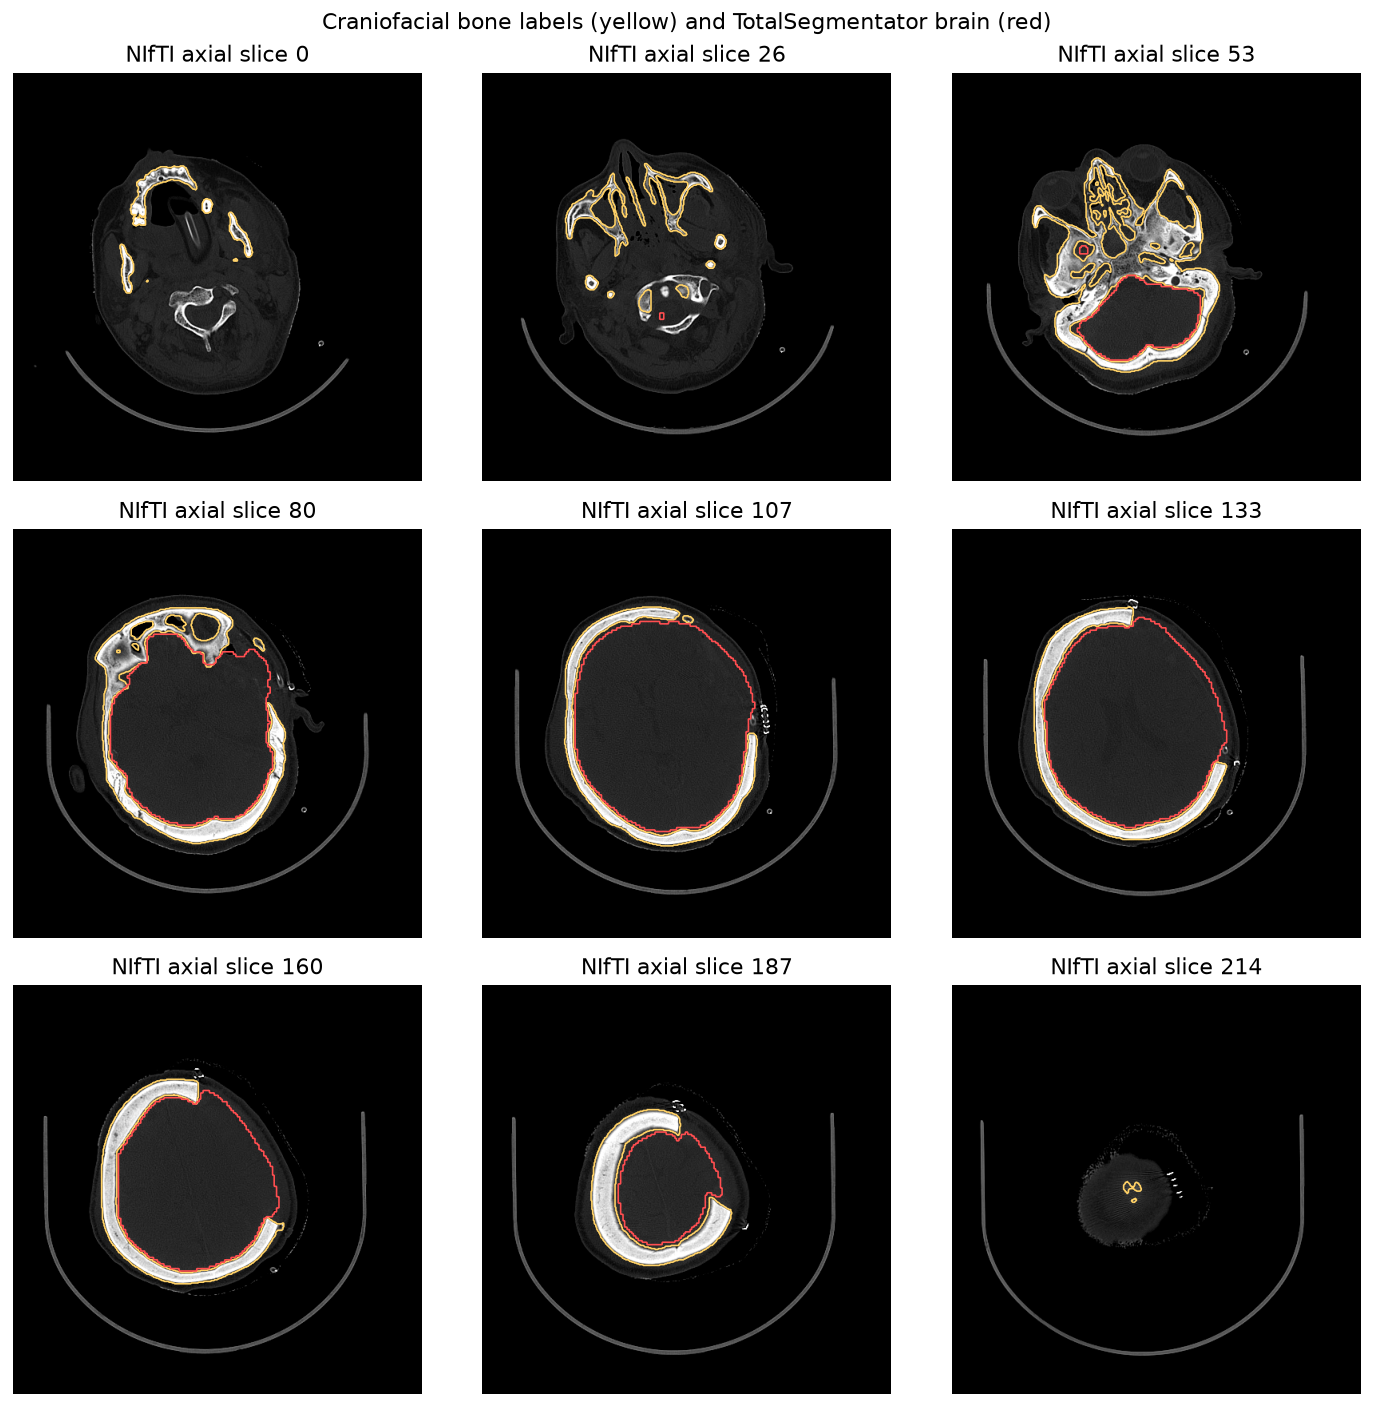

In [5]:
occupied = np.flatnonzero(np.any(sharp_skull_mask | brain_mask, axis=(0, 1)))
preview_slices = np.linspace(occupied[0], occupied[-1], 9, dtype=int)

overlay_figure, axes = plt.subplots(3, 3, figsize=(11, 11), dpi=130)
for axis, z in zip(axes.ravel(), preview_slices):
    ct_slice = np.rot90(np.asanyarray(bone_ct_image.dataobj[:, :, z], dtype=np.float32))
    skull_slice = np.rot90(sharp_skull_mask[:, :, z])
    brain_slice = np.rot90(brain_mask[:, :, z])
    axis.imshow(ct_slice, cmap="gray", vmin=-200, vmax=1400)
    if skull_slice.any():
        axis.contour(skull_slice, levels=[0.5], colors=["#ffd166"], linewidths=0.9)
    if brain_slice.any():
        axis.contour(brain_slice, levels=[0.5], colors=["#ff4e50"], linewidths=0.9)
    axis.set_title(f"NIfTI axial slice {z}")
    axis.axis("off")

overlay_figure.suptitle("Craniofacial bone labels (yellow) and TotalSegmentator brain (red)")
overlay_figure.tight_layout()
OVERLAY_PATH = OUTPUT_DIR / "CASE_001_sharp_skull_overlay.png"
overlay_figure.savefig(OVERLAY_PATH, bbox_inches="tight")
plt.show()

## Create the full-detail meshes

In [6]:
def prediction_to_mesh(mask, affine, step_size, smoothing_iterations):
    occupied_axes = []
    for axis in range(3):
        other_axes = tuple(index for index in range(3) if index != axis)
        occupied_axes.append(np.flatnonzero(np.any(mask, axis=other_axes)))
    if any(len(indices) == 0 for indices in occupied_axes):
        raise RuntimeError("Cannot mesh an empty prediction.")
    lower = np.maximum(np.asarray([indices[0] for indices in occupied_axes]) - 2, 0)
    upper = np.minimum(
        np.asarray([indices[-1] for indices in occupied_axes]) + 3,
        np.asarray(mask.shape),
    )
    crop_slices = tuple(slice(int(a), int(b)) for a, b in zip(lower, upper))
    cropped = mask[crop_slices]
    padded = np.pad(cropped, 1, mode="constant").astype(np.uint8, copy=False)
    vertices_voxel, faces, _normals, _values = measure.marching_cubes(
        padded,
        level=0.5,
        step_size=step_size,
        allow_degenerate=False,
    )
    vertices_voxel += lower.astype(np.float32) - 1.0
    vertices_world = nib.affines.apply_affine(affine, vertices_voxel).astype(np.float32)
    mesh = trimesh.Trimesh(
        vertices=vertices_world, faces=faces, process=True, validate=True
    )
    mesh.remove_unreferenced_vertices()
    if smoothing_iterations:
        trimesh.smoothing.filter_taubin(
            mesh, lamb=0.5, nu=0.525, iterations=smoothing_iterations
        )
    mesh.fix_normals(multibody=True)
    return mesh


# Reuse the already-exported high-detail skull when available. This makes a
# brain-only smoothing rerun much lighter on RAM.
if SKULL_GLB_CACHE.exists():
    cached_scene = trimesh.load(SKULL_GLB_CACHE, force="scene", process=False)
    sharp_skull_mesh = trimesh.util.concatenate(tuple(cached_scene.geometry.values()))
    print("Using cached high-detail skull mesh:", SKULL_GLB_CACHE)
else:
    sharp_skull_mesh = prediction_to_mesh(
        sharp_skull_mask, reference_image.affine, step_size=1, smoothing_iterations=2
    )
# Retain every predicted brain-mask voxel layer and apply only light smoothing.
brain_mesh = prediction_to_mesh(
    brain_mask, brain_image.affine, step_size=1, smoothing_iterations=6
)

del sharp_skull_mask, brain_mask, label_images
gc.collect()

sharp_skull_mesh.visual.face_colors = [232, 214, 179, 220]
brain_mesh.visual.face_colors = [217, 155, 145, 255]

print("Sharp skull:", f"{len(sharp_skull_mesh.vertices):,} vertices,", f"{len(sharp_skull_mesh.faces):,} triangles")
print("Brain:", f"{len(brain_mesh.vertices):,} vertices,", f"{len(brain_mesh.faces):,} triangles")
print("Sharp skull connected bodies:", len(sharp_skull_mesh.split(only_watertight=False)))

Using cached high-detail skull mesh: F:\csstdy\outputs\10_totalsegmentator_sharp_skull\meshes\CASE_001_totalsegmentator_sharp_skull.glb


Sharp skull: 624,131 vertices, 1,248,774 triangles
Brain: 236,274 vertices, 472,544 triangles


Sharp skull connected bodies: 22


## Export and show the combined sharper reconstruction

In [7]:
paths = {
    "sharp_skull_ply": MESH_DIR / "CASE_001_totalsegmentator_sharp_skull.ply",
    "sharp_skull_stl": MESH_DIR / "CASE_001_totalsegmentator_sharp_skull.stl",
    "sharp_skull_glb": MESH_DIR / "CASE_001_totalsegmentator_sharp_skull.glb",
    "brain_glb": MESH_DIR / "CASE_001_totalsegmentator_brain.glb",
    "combined_glb": MESH_DIR / "CASE_001_totalsegmentator_sharp_skull_and_brain.glb",
    "combined_html": OUTPUT_DIR / "CASE_001_totalsegmentator_sharp_skull_and_brain.html",
    "skull_html": OUTPUT_DIR / "CASE_001_totalsegmentator_sharp_skull_only.html",
    "brain_html": OUTPUT_DIR / "CASE_001_totalsegmentator_brain_only.html",
}

sharp_skull_mesh.export(paths["sharp_skull_ply"])
sharp_skull_mesh.export(paths["sharp_skull_stl"])
paths["sharp_skull_glb"].write_bytes(trimesh.Scene(sharp_skull_mesh).export(file_type="glb"))
paths["brain_glb"].write_bytes(trimesh.Scene(brain_mesh).export(file_type="glb"))

combined_scene = trimesh.Scene()
combined_scene.add_geometry(sharp_skull_mesh.copy(), node_name="sharp_skull", geom_name="sharp_skull")
combined_scene.add_geometry(brain_mesh.copy(), node_name="brain", geom_name="brain")
paths["combined_glb"].write_bytes(combined_scene.export(file_type="glb"))

skull_vertices = np.asarray(sharp_skull_mesh.vertices)
skull_faces = np.asarray(sharp_skull_mesh.faces)
brain_vertices = np.asarray(brain_mesh.vertices)
brain_faces = np.asarray(brain_mesh.faces)

def style_figure(figure, title):
    figure.update_layout(
        title=title,
        template="plotly_dark",
        width=950,
        height=780,
        margin=dict(l=0, r=0, t=60, b=0),
        legend=dict(x=0.02, y=0.98),
        scene=dict(
            aspectmode="data",
            xaxis_title="Patient R-L (mm)",
            yaxis_title="Patient A-P (mm)",
            zaxis_title="Patient I-S (mm)",
            xaxis=dict(showbackground=False),
            yaxis=dict(showbackground=False),
            zaxis=dict(showbackground=False),
            camera=dict(eye=dict(x=1.55, y=-1.55, z=1.15)),
        ),
    )
    return figure


combined_figure = go.Figure([
    go.Mesh3d(
        x=skull_vertices[:, 0], y=skull_vertices[:, 1], z=skull_vertices[:, 2],
        i=skull_faces[:, 0], j=skull_faces[:, 1], k=skull_faces[:, 2],
        name="Craniofacial skull + jaw + teeth", color="#e8d6b3", opacity=0.24,
        flatshading=False, hoverinfo="skip",
        lighting=dict(ambient=0.45, diffuse=0.72, specular=0.20, roughness=0.70),
    ),
    go.Mesh3d(
        x=brain_vertices[:, 0], y=brain_vertices[:, 1], z=brain_vertices[:, 2],
        i=brain_faces[:, 0], j=brain_faces[:, 1], k=brain_faces[:, 2],
        name="TotalSegmentator brain", color="#d99b91", opacity=1.0,
        flatshading=False, hoverinfo="skip",
        lighting=dict(ambient=0.44, diffuse=0.72, specular=0.18, roughness=0.78),
    ),
])
style_figure(combined_figure, "CASE_001 - Sharper DL Skull and Brain")
combined_figure.write_html(paths["combined_html"], include_plotlyjs=True, full_html=True)
display(IFrame(src=paths["combined_html"].as_uri(), width=950, height=780))
del combined_figure
gc.collect()

614

## Sharper skull-only reconstruction

In [8]:
skull_figure = go.Figure([go.Mesh3d(
    x=skull_vertices[:, 0], y=skull_vertices[:, 1], z=skull_vertices[:, 2],
    i=skull_faces[:, 0], j=skull_faces[:, 1], k=skull_faces[:, 2],
    name="Craniofacial skull + jaw + teeth", color="#e8d6b3", opacity=1.0,
    flatshading=False, hoverinfo="skip",
    lighting=dict(ambient=0.42, diffuse=0.74, specular=0.22, roughness=0.68),
)])
style_figure(skull_figure, "CASE_001 - Sharper TotalSegmentator Craniofacial Skull")
skull_figure.write_html(paths["skull_html"], include_plotlyjs=True, full_html=True)
display(IFrame(src=paths["skull_html"].as_uri(), width=950, height=780))
del skull_figure
gc.collect()

1969

## Brain-only reconstruction for comparison

In [9]:
brain_figure = go.Figure([go.Mesh3d(
    x=brain_vertices[:, 0], y=brain_vertices[:, 1], z=brain_vertices[:, 2],
    i=brain_faces[:, 0], j=brain_faces[:, 1], k=brain_faces[:, 2],
    name="TotalSegmentator brain", color="#d99b91", opacity=1.0,
    flatshading=False, hoverinfo="skip",
    lighting=dict(ambient=0.44, diffuse=0.72, specular=0.18, roughness=0.78),
)])
style_figure(brain_figure, "CASE_001 - TotalSegmentator Brain")
brain_figure.write_html(paths["brain_html"], include_plotlyjs=True, full_html=True)
display(IFrame(src=paths["brain_html"].as_uri(), width=950, height=780))
del brain_figure
gc.collect()

2001

## Reproducibility summary

In [10]:
summary = {
    "segmentation_method": "TotalSegmentator pretrained nnU-Net predictions only",
    "totalsegmentator_version": metadata.version("TotalSegmentator"),
    "nnunet_version": metadata.version("nnunetv2"),
    "device": torch.cuda.get_device_name(0),
    "skull_task": "craniofacial_structures",
    "skull_input_series": BONE_DICOM_DIR.name,
    "skull_labels_combined": CRANIOFACIAL_LABELS,
    "model_ran_during_this_execution": bool(model_ran_now),
    "inference_or_cache_seconds": inference_seconds,
    "label_voxels": label_voxels,
    "combined_bony_head": {
        "voxels": sharp_skull_voxels,
        "volume_ml": sharp_skull_volume_ml,
        "vertices": int(len(sharp_skull_mesh.vertices)),
        "triangles": int(len(sharp_skull_mesh.faces)),
        "watertight": bool(sharp_skull_mesh.is_watertight),
        "mesh_step_size": 1,
        "smoothing_iterations": 2,
    },
    "brain": {
        "source": str(PRIOR_BRAIN_NIFTI),
        "volume_ml": brain_volume_ml,
        "vertices": int(len(brain_mesh.vertices)),
        "triangles": int(len(brain_mesh.faces)),
        "watertight": bool(brain_mesh.is_watertight),
        "mesh_step_size": 1,
        "smoothing_iterations": 6,
    },
    "outputs": {name: str(path) for name, path in paths.items()},
    "overlay_path": str(OVERLAY_PATH),
    "totalsegmentator_report": str(REPORT_PATH),
    "total_notebook_seconds": time.time() - STARTED,
    "clinical_use": False,
}
SUMMARY_PATH.write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(json.dumps(summary, indent=2))

{
  "segmentation_method": "TotalSegmentator pretrained nnU-Net predictions only",
  "totalsegmentator_version": "2.18.0",
  "nnunet_version": "2.8.1",
  "device": "NVIDIA GeForce RTX 4060 Laptop GPU",
  "skull_task": "craniofacial_structures",
  "skull_input_series": "BONE_HR60F",
  "skull_labels_combined": [
    "skull",
    "mandible",
    "teeth_upper",
    "teeth_lower"
  ],
  "model_ran_during_this_execution": false,
  "inference_or_cache_seconds": 0.00013136863708496094,
  "label_voxels": {
    "skull": 2116682,
    "mandible": 33992,
    "teeth_upper": 5614,
    "teeth_lower": 0
  },
  "combined_bony_head": {
    "voxels": 2156288,
    "volume_ml": 499.4831513772786,
    "vertices": 624131,
    "triangles": 1248774,
    "watertight": true,
    "mesh_step_size": 1,
    "smoothing_iterations": 2
  },
  "brain": {
    "source": "F:\\csstdy\\outputs\\09_totalsegmentator_dl_skull_brain\\segmentations\\brain.nii.gz",
    "volume_ml": 1152.485433598391,
    "vertices": 236274,
    "tr